# Case Study 2 — Opportunity Bargains in New York City

How does accounting for rent change which neighborhoods rank highest for opportunity?
We first combine school performance, crime, and poverty into a neighborhood priority
index. We then add median rent and map the change in score for each neighborhood.

This notebook follows UrbanTrace's 2017 comparison and adds a second comparison that
keeps the baseline indicators in the same proportions when rent is introduced.
[Case study in the UrbanTrace paper](https://arxiv.org/html/2607.25124v1#S3.SS4) ·
[Published comparison](https://arxiv.org/html/2607.25124v1/fig_7_urbantrace.png)

## Setup

Use a Python kernel with the UrbanTrace backend dependencies and Matplotlib installed.
The notebook reads the seven GeoJSON files from the checkout's Git LFS catalog. Open it
from the repository root or the notebook directory. It calls UrbanTrace's plan runner and
priority index directly, with temporary storage for the run.

~~~sh
python -m pip install -r backend/requirements.txt ipykernel matplotlib
~~~

In [1]:
import sys
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from IPython.display import Image, display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, TwoSlopeNorm

start = Path.cwd()
root = next(
    (path for path in (start, *start.parents) if (path / "backend" / "plans.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open this notebook from inside the UrbanTrace checkout.")

sys.path.insert(0, str(root / "backend"))
import analysis
import plans
import urbanweave

data = root / "data"
print(f"Integration engine: urbanweave {urbanweave.__version__}")

Integration engine: urbanweave 0.1.0a2


## 1. Select the indicators and neighborhoods

Use the **2017** column for every layer, as shown in the published comparison. The inputs
come from two geographies. School and crime indicators use 59 Community Districts. Poverty
and median rent use 55 Sub-Borough Areas. Rent is the median gross rent series reported
in constant 2024 dollars in the local catalog.

| Indicator | Catalog layer | Source geography | Higher opportunity |
|---|---|---|---|
| Fourth-grade math proficiency | `NYC_students_performing_math` | Community District | Higher |
| Fourth-grade English language arts proficiency | `NYC_students_performing_english_language_arts` | Community District | Higher |
| Serious violent crime per 1,000 residents | Derived from `NYC_crime_rate_per_1000_residents` and `NYC_crime_rate_property` | Community District | Lower |
| Serious property crime per 1,000 residents | `NYC_crime_rate_property` | Community District | Lower |
| Poverty rate | `NYC_poverty_rate` | Sub-Borough Area | Lower |
| Median gross rent | `NYC_median_rent` | Sub-Borough Area | Lower |

The study area is the set of **197 residential 2020 Neighborhood Tabulation Areas** (NTAs).
Use the same set for both scenarios so the normalization bounds are comparable. Each NTA
is identified by its `nta2020` code.
[NYC Planning NTA metadata](https://s-media.nyc.gov/agencies/dcp/assets/files/pdf/data-tools/bytes/nynta2020_metadata.pdf)

The Furman Center splits serious crime into violent and property offenses and reports
the rates per 1,000 residents. We derive the violent rate as total serious crime minus
serious property crime. The check below confirms that the two series have the same
district IDs and geometries and complete 2017 values. With the same overlap weights,
subtracting the two aligned NTA rates gives the same result as aligning their difference.
[Furman Center crime indicator definitions](https://www.furmancenter.org/soc-report/state-of-new-york-citys-housing-and-neighborhoods-in-2019/rankings-data-and-methods/)

In [2]:
year = "2017"
nta_layer = "NTA_Neighborhood_Tabulation_Areas"
layers = {
    "math": "NYC_students_performing_math",
    "ela": "NYC_students_performing_english_language_arts",
    "poverty": "NYC_poverty_rate",
    "all_crime": "NYC_crime_rate_per_1000_residents",
    "property_crime": "NYC_crime_rate_property",
    "rent": "NYC_median_rent",
}
files = {name: data / "geojson" / f"{stem}.geojson" for name, stem in layers.items()}
for path in (*files.values(), data / "geojson" / f"{nta_layer}.geojson"):
    if not path.is_file():
        raise FileNotFoundError(f"Missing catalog file: {path}. See the repository setup.")
    with path.open("rb") as stream:
        if stream.read(64).startswith(b"version https://git-lfs.github.com/spec/"):
            raise ValueError(f"Fetch the Git LFS data for {path.name} before running this notebook.")

rows = []
for name, path in files.items():
    layer = gpd.read_file(path, columns=[year])
    observed = pd.to_numeric(layer[year], errors="coerce")
    assert np.isfinite(observed).all(), f"Incomplete {year} data in {name}"
    rows.append({"Indicator": name, "Source areas": len(layer)})
display(pd.DataFrame(rows).set_index("Indicator"))

def crime_series(name):
    return (
        gpd.read_file(files[name], columns=["BoroCD", year])
        .set_index("BoroCD")
        .sort_index()
    )

total, property_only = (crime_series(name) for name in ("all_crime", "property_crime"))
assert total.index.is_unique and total.index.equals(property_only.index) and len(total) == 59
assert total.crs == property_only.crs
assert shapely.equals_exact(total.geometry, property_only.geometry, tolerance=0).all()
assert (total[year] - property_only[year]).ge(0).all()

,Source areas
Indicator,
math,59
ela,59
poverty,55
all_crime,59
property_crime,59
rent,55


## 2. Align the layers to the same NTAs

Each indicator is intensive. Use `area_overlap` and `weighted_mean` for the direct
polygon-to-polygon transfer. The weight is the area each source polygon shares with the
target NTA. UrbanTrace repairs invalid geometries before matching and records those
repairs. The resulting values are estimates based on the source areas. For example, the
NTA rent value is an area-weighted average of the overlapping Sub-Borough medians.

In [3]:
study_area = {"kind": "zones", "dataset": nta_layer, "column": "ntatype", "values": ["0"]}
plan = {
    "version": 1,
    "sources": {
        name: {
            "kind": "vector",
            "columns": {year: {"kind": "intensive"}},
            "urbantrace": {"dataset": stem},
        }
        for name, stem in layers.items()
    },
    "targets": {
        "nta": {"kind": "zones", "urbantrace": {"dataset": nta_layer, "id_column": "nta2020"}}
    },
    "steps": [
        {
            "id": name,
            "source": name,
            "match": {"method": "area_overlap", "target": "nta"},
            "aggregate": [{"method": "weighted_mean", "column": year, "as": name}],
        }
        for name in layers
    ],
}
baseline_inputs = [name for name in layers if name != "rent"]
derived = [
    {
        "id": name,
        "inputs": inputs,
        "expression": "all_crime - property_crime",
        "as": "violent_crime",
        "kind": "intensive",
    }
    for name, inputs in (
        ("baseline", baseline_inputs),
        ("with_rent", list(layers)),
    )
]

with TemporaryDirectory(prefix="urbantrace-opportunity-") as cache:
    checks = plans.validate(data, plan, study_area, cache)
    if not checks["ok"]:
        raise ValueError(checks["problems"])
    run = plans.run(data, plan, study_area, cache, outputs=list(layers), derived=derived)

baseline_result = run["steps"]["baseline"]
rent_result = run["steps"]["with_rent"]
baseline_nta = pd.DataFrame(baseline_result["columns"], index=baseline_result["target_ids"])
rent_nta = pd.DataFrame(rent_result["columns"], index=rent_result["target_ids"])
pd.testing.assert_frame_equal(baseline_nta, rent_nta[baseline_nta.columns])
assert len(rent_nta) == 197 and rent_nta.index.is_unique
assert np.isfinite(rent_nta.to_numpy(dtype=float)).all()
print(f"{len(rent_nta)} residential NTAs have complete data in both scenarios.")
repairs = {
    name: result["repaired_geometries"]["count"]
    for name, result in run["inputs"].items()
    if result.get("repaired_geometries")
}
print("Source geometry repairs:", repairs)

197 residential NTAs have complete data in both scenarios.
Source geometry repairs: {'poverty': 2, 'rent': 2}


## 3. Score three scenarios

UrbanTrace normalizes each indicator to 0–1 over the study area. Higher school
proficiency raises the score. Lower crime, poverty, and rent raise it after inversion.
The score is the weighted average of these components.

The **baseline** and **published-weight comparison** use the rounded labels shown in the
paper. The figure truncates the paired school and crime names. Here we assign them in
the order math, English language arts, violent crime, property crime. UrbanTrace
normalizes each set of weights to sum to one. These choices make the first comparison
an approximate recreation of the figure.

In the **rent-only comparison**, rent receives 27% and the five baseline indicators
share the remaining 73% in their original proportions. The delta from the baseline
then isolates the effect of adding rent under this scoring rule.
[Published comparison](https://arxiv.org/html/2607.25124v1/fig_7_urbantrace.png)

In [4]:
baseline_weights = {"math": 28, "ela": 26, "poverty": 25, "violent_crime": 12, "property_crime": 10}
published_weights = {
    "math": 21, "ela": 21, "poverty": 12, "violent_crime": 8, "property_crime": 10, "rent": 27,
}
rent_share = 0.27
rent_only_weights = {
    name: weight / sum(baseline_weights.values()) * (1 - rent_share)
    for name, weight in baseline_weights.items()
}
rent_only_weights["rent"] = rent_share
scenarios = {
    "Baseline": baseline_weights,
    "Published weights + rent": published_weights,
    "Rent only": rent_only_weights,
}
display(
    pd.DataFrame({
        name: {column: 100 * weight / sum(weights.values()) for column, weight in weights.items()}
        for name, weights in scenarios.items()
    }).fillna(0).round(2).rename_axis("Indicator · weights in %")
)

def priority(weights):
    variables = [
        {
            "column": name,
            "weight": weight,
            "direction": "normal" if name in {"math", "ela"} else "inverted",
        }
        for name, weight in weights.items()
    ]
    return analysis.priority(rent_nta.to_dict("list"), variables)

scores = pd.DataFrame(
    {"baseline": priority(baseline_weights), "published": priority(published_weights),
     "rent_only": priority(rent_only_weights)},
    index=rent_nta.index,
)
scores["published_delta"] = scores["published"] - scores["baseline"]
scores["rent_only_delta"] = scores["rent_only"] - scores["baseline"]
assert scores[["baseline", "published", "rent_only"]].apply(lambda x: x.between(0, 1).all()).all()
assert np.allclose(scores["rent_only"], (1 - rent_share) * scores["baseline"] + rent_share * (
    1 - (rent_nta["rent"] - rent_nta["rent"].min()) / (rent_nta["rent"].max() - rent_nta["rent"].min())
), rtol=0, atol=2e-6)

,Baseline,Published weights + rent,Rent only
Indicator · weights in %,,,
math,27.72,21.21,20.24
ela,25.74,21.21,18.79
poverty,24.75,12.12,18.07
violent_crime,11.88,8.08,8.67
property_crime,9.90,10.10,7.23
rent,0.00,27.27,27.00


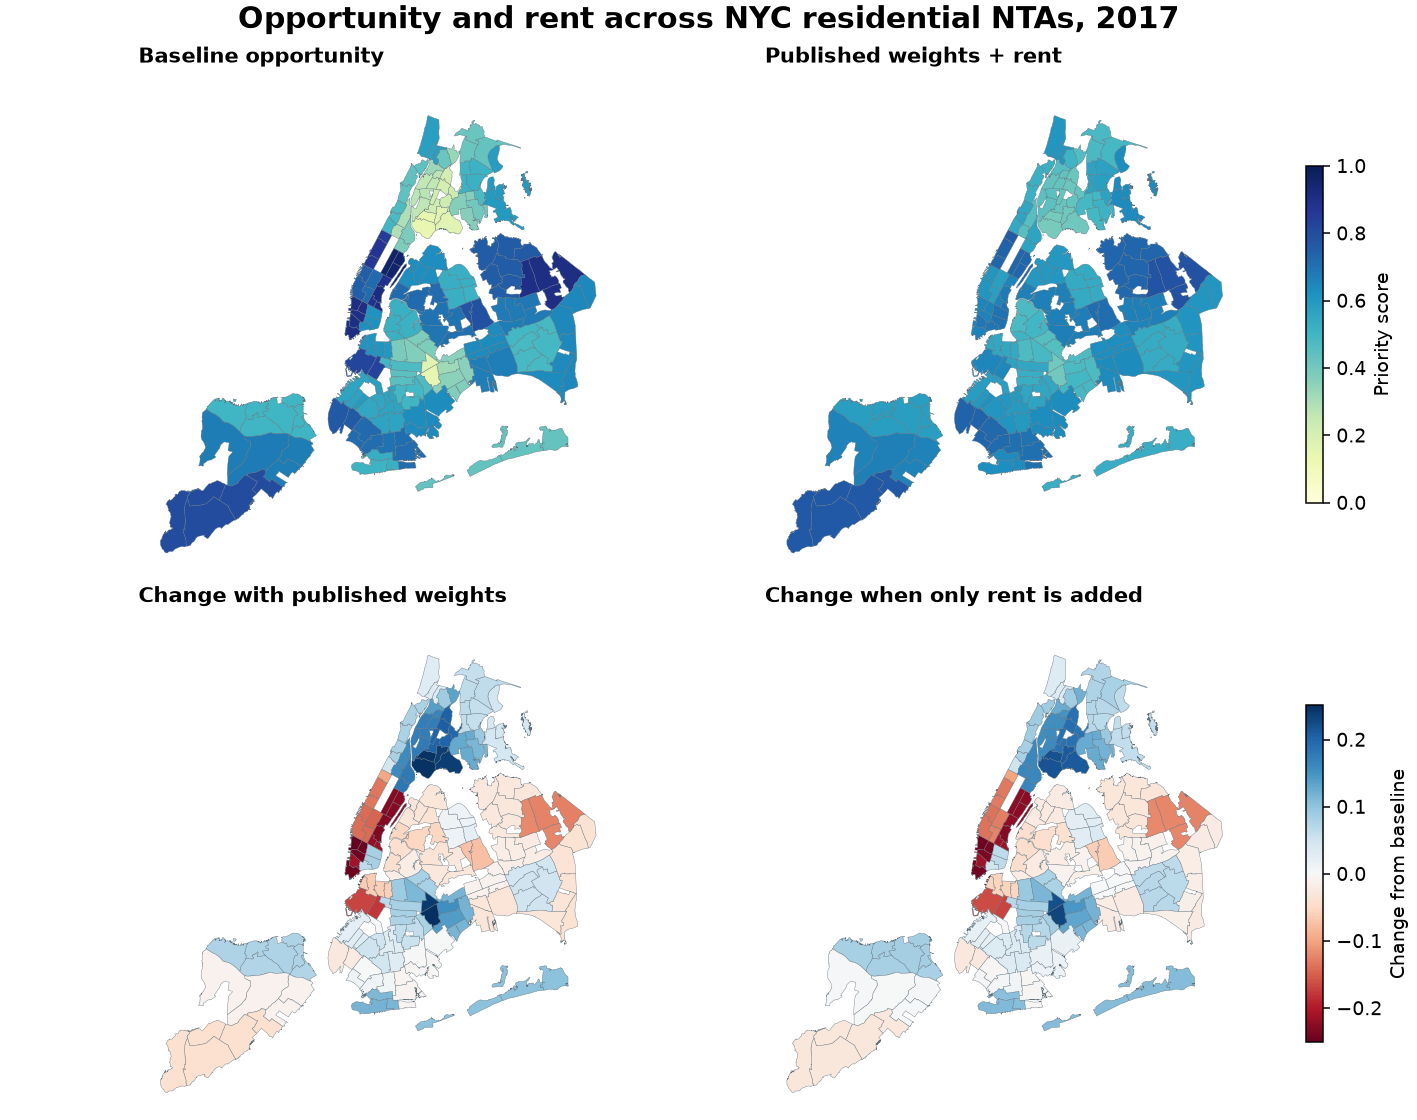

In [5]:
geometry = gpd.GeoDataFrame.from_features(rent_result["geojson"], crs="EPSG:4326")
geometry = geometry.set_index("zone_id")[["label", "geometry"]]
assert geometry.index.is_unique and set(geometry.index) == set(scores.index)
mapped = geometry.join(scores).to_crs("EPSG:32618")

limit = float(scores[["published_delta", "rent_only_delta"]].abs().max().max())
score_scale = Normalize(vmin=0, vmax=1)
delta_scale = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.3), layout="constrained")
fig.suptitle("Opportunity and rent across NYC residential NTAs, 2017", fontsize=16, weight="bold")
panels = [
    ("baseline", "Baseline opportunity", "YlGnBu", score_scale),
    ("published", "Published weights + rent", "YlGnBu", score_scale),
    ("published_delta", "Change with published weights", "RdBu", delta_scale),
    ("rent_only_delta", "Change when only rent is added", "RdBu", delta_scale),
]
for ax, (column, title, cmap, norm) in zip(axes.flat, panels):
    mapped.plot(column=column, ax=ax, cmap=cmap, norm=norm, linewidth=0.20, edgecolor="#60717b")
    ax.set_title(title, loc="left", fontsize=11, weight="bold")
    ax.set_axis_off()
fig.colorbar(ScalarMappable(norm=score_scale, cmap="YlGnBu"), ax=axes[0], shrink=0.70,
             label="Priority score")
fig.colorbar(ScalarMappable(norm=delta_scale, cmap="RdBu"), ax=axes[1], shrink=0.70,
             label="Change from baseline")
png = BytesIO()
fig.savefig(png, format="png", dpi=135, facecolor="white")
display(Image(data=png.getvalue()))
plt.close(fig)

In [6]:
deltas = scores[["published_delta", "rent_only_delta"]].rename(
    columns={"published_delta": "Published weights + rent", "rent_only_delta": "Rent only"}
)
display(pd.DataFrame({
    "Increased": deltas.gt(0).sum(),
    "Decreased": deltas.lt(0).sum(),
    "Unchanged": deltas.eq(0).sum(),
    "Largest increase": deltas.max(),
    "Largest decrease": deltas.min(),
}).round(3))

extremes = pd.concat([
    mapped.nlargest(3, "published_delta"),
    mapped.nsmallest(3, "published_delta"),
])[["label", "baseline", "published", "published_delta", "rent_only_delta"]]
display(extremes.rename(columns={
    "label": "Neighborhood",
    "baseline": "Baseline",
    "published": "Published weights + rent",
    "published_delta": "Published change",
    "rent_only_delta": "Rent-only change",
}).round(3).rename_axis("NTA"))

,Increased,Decreased,Unchanged,Largest increase,Largest decrease
Published weights + rent,107,90,0,0.251,-0.250
Rent only,116,81,0,0.230,-0.244


,Neighborhood,Baseline,Published weights + rent,Published change,Rent-only change
NTA,,,,,
BK1602,Brownsville,0.149,0.400,0.251,0.230
BX0102,Melrose,0.142,0.391,0.249,0.218
BX0101,Mott Haven-Port Morris,0.143,0.390,0.248,0.217
MN0203,West Village,0.904,0.654,-0.250,-0.244
MN0101,Financial District-Battery Park City,0.904,0.658,-0.246,-0.242
MN0202,Greenwich Village,0.902,0.656,-0.246,-0.240


## 4. Interpret the delta map

Under the rounded published weights, scores rose in **107** residential NTAs and fell
in **90**. Brownsville rose from **0.149** to **0.400**, while West Village fell from
**0.904** to **0.654**. Both shifts had the same direction in the rent-only
comparison. Blue shows a gain relative to the baseline and red shows a loss.

The published-weight scenario changes both the rent contribution and the mix of
education, crime, and poverty weights. The rent-only scenario holds the baseline mix
fixed. Comparing the two delta maps shows where reweighting the existing indicators
changes the result.

A positive delta is a gain relative to the baseline. Read it alongside the final
opportunity score to see where affordability and opportunity coincide. The scores
describe the selected indicators and weights. As area-weighted estimates, they also
inherit the assumption that the source-area value applies throughout that area.

This comparison follows UrbanTrace's affordability-as-an-indicator approach. The
original SVP research identifies bargains using rents below what a model predicts
given opportunity and housing characteristics.
[Original SVP study](https://www.furmancenter.org/publication/planning-for-opportunity-how-planners-can-expand-access-to-affordable-opportunity-bargain-areas/)

## Repeat the workflow on the UrbanTrace canvas

1. Choose the NTA layer as the study area and select `ntatype = 0`. Add the six
   catalog inputs and use the same NTA target for each Step.
2. For each Step select the `2017` column as intensive, choose area overlap and
   weighted mean, and give the output the corresponding alias used in the notebook.
3. Create two **Combine & Calculate** nodes using the baseline and rent inputs above.
   In each, enter `all_crime - property_crime` and name the output `violent_crime`.
4. In the two Result Maps set the weights and directions from the table. Give the
   intermediate `all_crime` column zero weight. Connect the baseline map first and
   the map with rent second to the **Spatial Delta Map**, so its sign is rent minus
   baseline. Check both maps use the same 197 NTA codes and compare several signed
   differences with the table above.